## 직접 예측

In [36]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import torch.nn as nn
import torch.optim as optim

# --- 1. 베이스라인을 위한 데이터 전처리 ---
# Product_Number를 원-핫 인코딩으로 변환하는 것이 핵심입니다.

print("--- 베이스라인 모델을 위한 데이터 전처리 시작 ---")

# 원본 데이터프레임 다시 로드 (혹은 복사해서 사용)
df_base = pd.read_csv(FILE_PATH)

# 기존 전처리 과정 일부 재사용
df_base['DateTime'] = pd.to_datetime(df_base['DateTime'], format='mixed')
df_base['month_sin'] = np.sin(2 * np.pi * df_base['DateTime'].dt.month/12)
df_base['month_cos'] = np.cos(2 * np.pi * df_base['DateTime'].dt.month/12)
df_base['day_sin'] = np.sin(2 * np.pi * df_base['DateTime'].dt.day/31)
df_base['day_cos'] = np.cos(2 * np.pi * df_base['DateTime'].dt.day/31)

scaler = MinMaxScaler()
numeric_cols_for_scaling = [col for col in df_base.columns if '수주량' in col and col != 'T+4일 예정 수주량'] + ['Temperature', 'Humidity']
cols_to_scale = [col for col in numeric_cols_for_scaling if col in df_base.columns]
if cols_to_scale:
    df_base[cols_to_scale] = scaler.fit_transform(df_base[cols_to_scale])

# ✨✨✨ 베이스라인의 핵심: One-Hot Encoding ✨✨✨
df_base = pd.get_dummies(df_base, columns=['Product_Number', 'DoW'], prefix=['Product', 'DoW'])

# 입력(X)과 타겟(y) 정의
target_base = df_base['T+4일 예정 수주량'].values
features_base = df_base.drop(columns=['T+4일 예정 수주량', 'DateTime']).astype(np.float32).values

print(f"원-핫 인코딩 후 피처 수: {features_base.shape[1]}")


# --- 2. 베이스라인 모델을 위한 Dataset 및 DataLoader ---

class BaselineDataset(Dataset):
    def __init__(self, features, targets):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return self.features[idx], self.targets[idx]

# 기존과 동일한 분할 비율로 데이터 분리
X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(
    features_base, target_base, test_size=TEST_SPLIT_RATIO, random_state=42
)

train_dataset_base = BaselineDataset(X_train_base, y_train_base)
test_dataset_base = BaselineDataset(X_test_base, y_test_base)

train_loader_base = DataLoader(train_dataset_base, batch_size=BATCH_SIZE, shuffle=True)
test_loader_base = DataLoader(test_dataset_base, batch_size=BATCH_SIZE, shuffle=False)


# --- 3. 베이스라인 모델 아키텍처 정의 ---
# 임베딩 층이 없는 단순 MLP 모델

class BaselineModel(nn.Module):
    def __init__(self, num_features):
        super(BaselineModel, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(num_features, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.layers(x)

# --- 4. 베이스라인 모델 학습 및 평가 ---

baseline_model = BaselineModel(num_features=X_train_base.shape[1]).to(DEVICE)
criterion_base = nn.MSELoss()
optimizer_base = optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)

print("\n--- 베이스라인 모델 학습 시작 ---")
for epoch in range(EPOCHS):
    baseline_model.train()
    for X_batch, y_batch in train_loader_base:
        X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
        
        optimizer_base.zero_grad()
        outputs = baseline_model(X_batch)
        loss = criterion_base(outputs.squeeze(), y_batch)
        loss.backward()
        optimizer_base.step()
        
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {loss.item():.4f}")

print("\n--- 베이스라인 모델 평가 ---")
baseline_model.eval()
base_predictions, base_targets = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader_base:
        outputs = baseline_model(X_batch.to(DEVICE)).squeeze().cpu()
        base_predictions.extend(outputs.numpy())
        base_targets.extend(y_batch.numpy())

base_predictions = np.array(base_predictions)
base_targets = np.array(base_targets)
baseline_rmse = np.sqrt(np.mean((base_targets - base_predictions)**2))

print("\n" + "="*40)
print(f"📊 베이스라인 모델 최종 RMSE: {baseline_rmse:.4f}")
print("="*40)

# 이전 임베딩 모델의 RMSE와 이 값을 비교해보세요.
# print(f"참고: 임베딩 모델 RMSE: {test_rmse:.4f}") # 이전 셀에서 계산한 test_rmse 변수

--- 베이스라인 모델을 위한 데이터 전처리 시작 ---
원-핫 인코딩 후 피처 수: 144


NameError: name 'TEST_SPLIT_RATIO' is not defined

In [1]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.manifold import TSNE
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 2번 파일에서 정의한 모델 아키텍처를 불러옵니다.
from model import EmbeddingModel

# PyTorch를 위한 커스텀 데이터셋 클래스
class CustomDataset(Dataset):
    def __init__(self, product_indices, other_features, targets):
        self.product_indices = torch.tensor(product_indices, dtype=torch.long)
        self.other_features = torch.tensor(other_features, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return (
            self.product_indices[idx],
            self.other_features[idx],
            self.targets[idx]
        )

def preprocess_data(file_path):
    """데이터를 불러와 전처리하는 함수"""
    df = pd.read_csv(file_path)
    
    product_ids = df['Product_Number'].unique()
    product_map = {name: i for i, name in enumerate(product_ids)}
    # 시각화를 위해 인덱스->이름 역방향 맵도 생성
    idx_to_product_map = {i: name for name, i in product_map.items()}
    df['Product_Index'] = df['Product_Number'].map(product_map)
    num_unique_products = len(product_ids)

    df['DateTime'] = pd.to_datetime(df['DateTime'], format='mixed')
    df['month_sin'] = np.sin(2 * np.pi * df['DateTime'].dt.month/12)
    df['month_cos'] = np.cos(2 * np.pi * df['DateTime'].dt.month/12)
    df['day_sin'] = np.sin(2 * np.pi * df['DateTime'].dt.day/31)
    df['day_cos'] = np.cos(2 * np.pi * df['DateTime'].dt.day/31)

    df = pd.get_dummies(df, columns=['DoW'], prefix='DoW')

    scaler = MinMaxScaler()
    numeric_cols_for_scaling = [col for col in df.columns if '수주량' in col and col != 'T+4일 예정 수주량'] + ['Temperature', 'Humidity']
    cols_to_scale = [col for col in numeric_cols_for_scaling if col in df.columns]
    df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

    product_input = df['Product_Index'].values
    cols_to_exclude = ['Product_Number', 'Product_Index', 'DateTime', 'T+4일 예정 수주량']
    other_feature_cols = [col for col in df.columns if col not in cols_to_exclude]
    other_inputs = df[other_feature_cols].astype(np.float32).values
    
    target = df['T+4일 예정 수주량'].values

    print(f"전체 데이터 샘플 수: {len(df)}")
    print(f"고유 제품 수: {num_unique_products}")
    print(f"제품 외 피처 수: {other_inputs.shape[1]}")
    
    return product_input, other_inputs, target, num_unique_products, idx_to_product_map

In [2]:
# --- 하이퍼파라미터 및 설정 ---
FILE_PATH = 'data/사출성형_공급망최적화.csv'
EMBEDDING_DIM = 32
LEARNING_RATE = 0.005
EPOCHS = 100
BATCH_SIZE = 128
TEST_SPLIT_RATIO = 0.2
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")

# 1. 데이터 전처리
p_data, o_data, target, num_products, idx_to_product = preprocess_data(FILE_PATH)

# 2. 학습/테스트 데이터 분리
p_train, p_test, o_train, o_test, y_train, y_test = train_test_split(
    p_data, o_data, target, test_size=TEST_SPLIT_RATIO, random_state=42
)

# 3. PyTorch Dataset 및 DataLoader 생성
train_dataset = CustomDataset(p_train, o_train, y_train)
test_dataset = CustomDataset(p_test, o_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 4. 모델, 손실함수, 옵티마이저 정의
num_other_features = o_train.shape[1]
model = EmbeddingModel(
    num_unique_products=num_products,
    embedding_dim=EMBEDDING_DIM,
    num_other_features=num_other_features
).to(DEVICE)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# 5. 모델 학습 (이전과 동일)
print("\n--- 모델 학습 시작 ---")
for epoch in range(EPOCHS):
    model.train()
    for p_batch, o_batch, y_batch in train_loader:
        p_batch, o_batch, y_batch = p_batch.to(DEVICE), o_batch.to(DEVICE), y_batch.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(p_batch, o_batch)
        loss = criterion(outputs.squeeze(), y_batch)
        loss.backward()
        optimizer.step()
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {loss.item():.4f}")

Using device: cpu
전체 데이터 샘플 수: 34617
고유 제품 수: 117
제품 외 피처 수: 27

--- 모델 학습 시작 ---
Epoch [10/100], Loss: 2676.7229
Epoch [20/100], Loss: 1721.2209
Epoch [30/100], Loss: 911.0659
Epoch [40/100], Loss: 2304.1553
Epoch [50/100], Loss: 451.0934
Epoch [60/100], Loss: 628.1913
Epoch [70/100], Loss: 793.2020
Epoch [80/100], Loss: 2932.7178
Epoch [90/100], Loss: 779.1221
Epoch [100/100], Loss: 576.1334



--- 모델 평가 ---
테스트 데이터 손실(MSE): 316.4668
테스트 데이터 RMSE: 17.7895

--- 시각화 결과 생성 ---
'prediction_vs_actual.png' 저장 완료
'residual_plot.png' 저장 완료
'product_embedding_visualization.png' 저장 완료


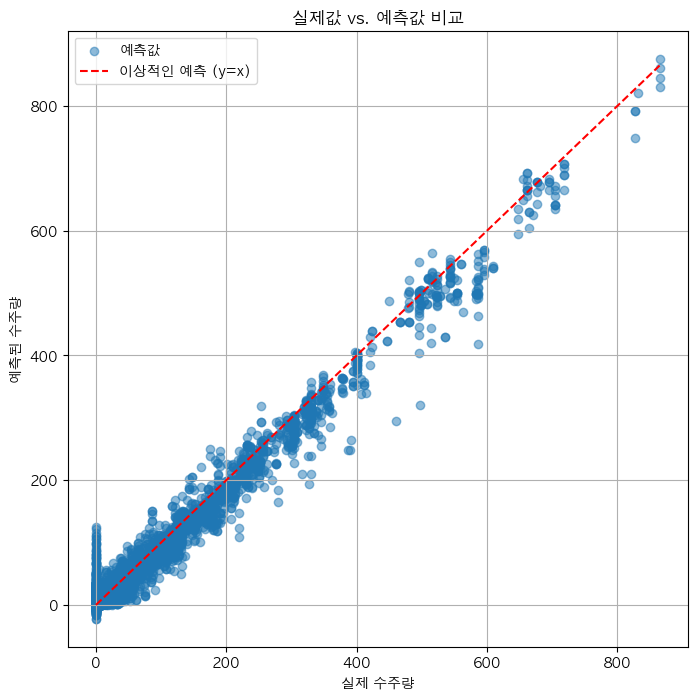

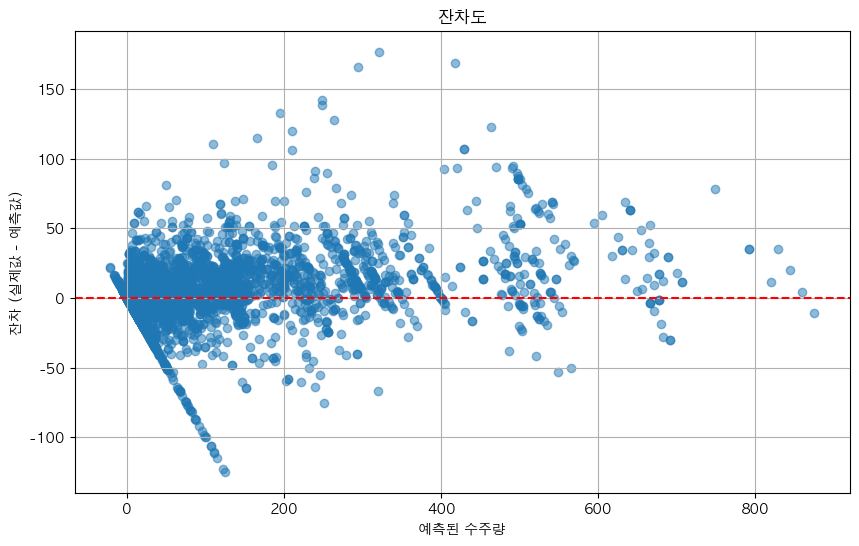

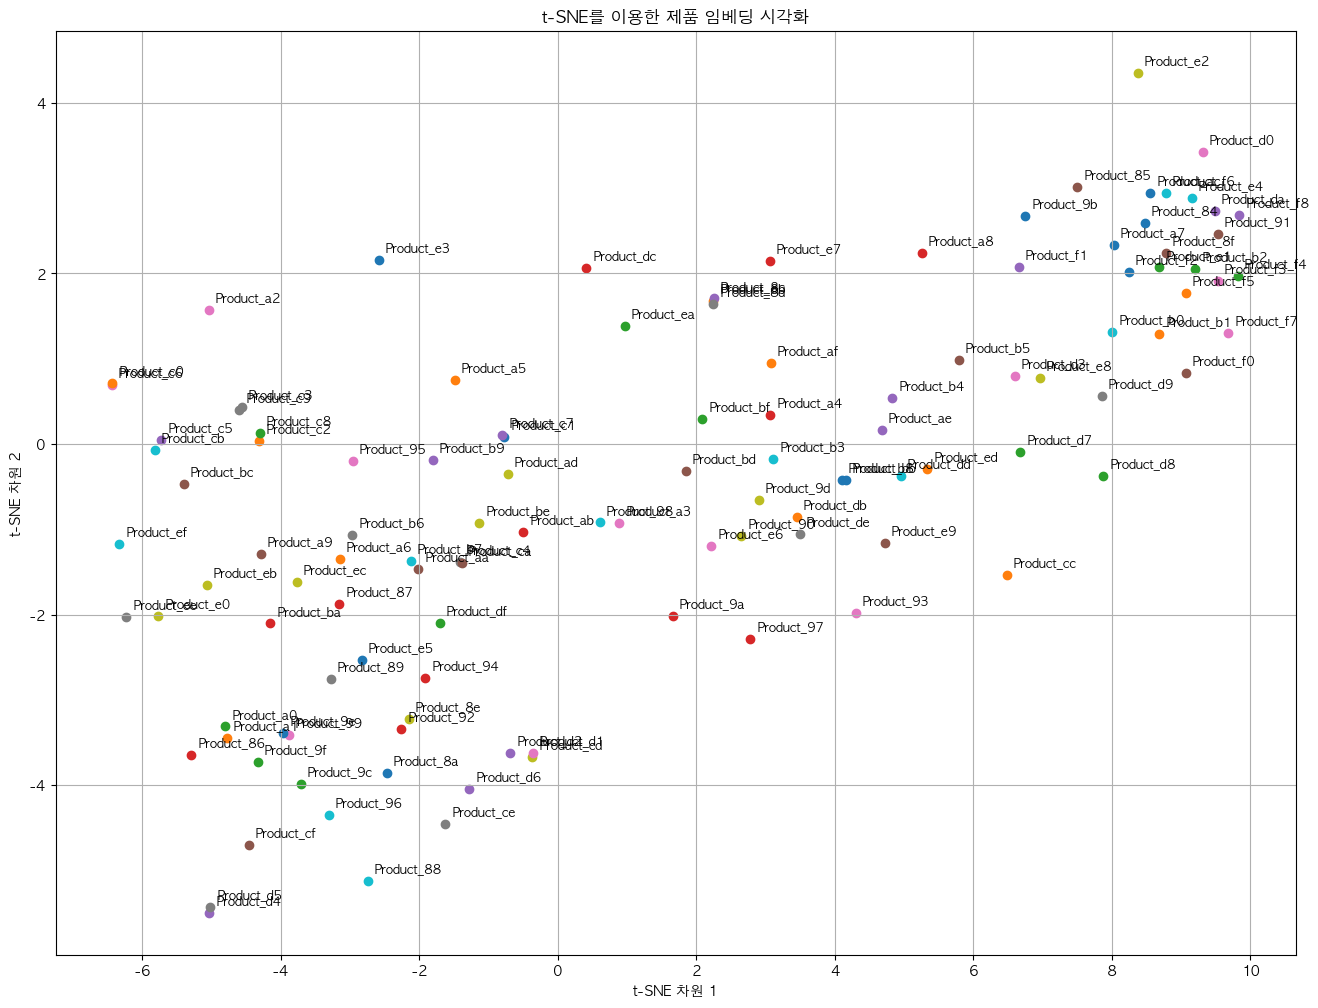

In [3]:
# 6. 모델 평가 및 전체 예측값 얻기
print("\n--- 모델 평가 ---")
model.eval()
all_predictions = []
all_targets = []
with torch.no_grad():
    for p_batch, o_batch, y_batch in test_loader:
        p_batch, o_batch = p_batch.to(DEVICE), o_batch.to(DEVICE)
        outputs = model(p_batch, o_batch).squeeze().cpu().numpy()
        all_predictions.extend(outputs)
        all_targets.extend(y_batch.numpy())

all_predictions = np.array(all_predictions)
all_targets = np.array(all_targets)
test_mse = np.mean((all_targets - all_predictions)**2)
print(f"테스트 데이터 손실(MSE): {test_mse:.4f}")
print(f"테스트 데이터 RMSE: {np.sqrt(test_mse):.4f}")

# --- ✨✨✨ 시각화 섹션 ✨✨✨ ---
print("\n--- 시각화 결과 생성 ---")

# 한글 폰트 설정 (파일이 없는 경우, 시스템에 맞는 폰트 경로를 지정해야 합니다)
# 예: Windows -> 'c:/Windows/Fonts/malgun.ttf'
# 예: macOS -> '/System/Library/Fonts/Supplemental/AppleGothic.ttf'
try:
    plt.rc('font', family='AppleGothic') 
    plt.rc('axes', unicode_minus=False) # 마이너스 폰트 깨짐 방지
except:
    print("한글 폰트를 찾을 수 없습니다. 영문으로 출력됩니다.")

# 1. 실제값 vs 예측값 비교
plt.figure(figsize=(8, 8))
plt.scatter(all_targets, all_predictions, alpha=0.5, label='예측값')
plt.plot([min(all_targets), max(all_targets)], [min(all_targets), max(all_targets)], 'r--', label='이상적인 예측 (y=x)')
plt.title('실제값 vs. 예측값 비교')
plt.xlabel('실제 수주량')
plt.ylabel('예측된 수주량')
plt.legend()
plt.grid(True)
plt.savefig('prediction_vs_actual.png')
print("'prediction_vs_actual.png' 저장 완료")

# 2. 잔차도 (Residual Plot)
residuals = all_targets - all_predictions
plt.figure(figsize=(10, 6))
plt.scatter(all_predictions, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('잔차도')
plt.xlabel('예측된 수주량')
plt.ylabel('잔차 (실제값 - 예측값)')
plt.grid(True)
plt.savefig('residual_plot.png')
print("'residual_plot.png' 저장 완료")

# 3. 제품 임베딩 시각화 (t-SNE)
# 학습된 임베딩 가중치 추출
embeddings = model.product_embedding.weight.data.cpu().numpy()

# t-SNE로 2차원으로 차원 축소
tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, num_products-1))
embeddings_2d = tsne.fit_transform(embeddings)

plt.figure(figsize=(16, 12))
for i, (x, y) in enumerate(embeddings_2d):
    plt.scatter(x, y)
    plt.text(x + 0.1, y + 0.1, idx_to_product[i], fontsize=9)

plt.title('t-SNE를 이용한 제품 임베딩 시각화')
plt.xlabel('t-SNE 차원 1')
plt.ylabel('t-SNE 차원 2')
plt.grid(True)
plt.savefig('product_embedding_visualization.png')
print("'product_embedding_visualization.png' 저장 완료")

## 차분 예측

In [35]:
# --- 1. 차분을 적용한 데이터 전처리 (수정된 버전) ---

print("--- 차분(Differencing)을 적용한 베이스라인 모델 준비 ---")

# 원본 데이터를 먼저 불러와 차분 타겟과 평가용 값을 저장합니다.
df_orig = pd.read_csv(FILE_PATH)
target_diff = df_orig['T+4일 예정 수주량'].values - df_orig['T+3일 예정 수주량'].values
original_t3_values = df_orig['T+3일 예정 수주량'].values
original_t4_values = df_orig['T+4일 예정 수주량'].values

# 피처 엔지니어링을 위한 데이터프레임
df_diff = pd.read_csv(FILE_PATH)

# 기존 전처리 과정 재사용
df_diff['DateTime'] = pd.to_datetime(df_diff['DateTime'], format='mixed')
df_diff['month_sin'] = np.sin(2 * np.pi * df_diff['DateTime'].dt.month/12)
df_diff['month_cos'] = np.cos(2 * np.pi * df_diff['DateTime'].dt.month/12)
df_diff['day_sin'] = np.sin(2 * np.pi * df_diff['DateTime'].dt.day/31)
df_diff['day_cos'] = np.cos(2 * np.pi * df_diff['DateTime'].dt.day/31)

scaler = MinMaxScaler()
numeric_cols = [col for col in df_diff.columns if '수주량' in col] + ['Temperature', 'Humidity']
numeric_cols.remove('T+4일 예정 수주량') # 타겟은 스케일링에서 제외
cols_to_scale = [col for col in numeric_cols if col in df_diff.columns]
if cols_to_scale:
    df_diff[cols_to_scale] = scaler.fit_transform(df_diff[cols_to_scale])

df_diff = pd.get_dummies(df_diff, columns=['Product_Number', 'DoW'], prefix=['Product', 'DoW'])

# 입력 피처 정의: T+4(타겟)만 제외하고 모두 사용
features_diff = df_diff.drop(columns=['T+4일 예정 수주량', 'DateTime']).astype(np.float32).values

# --- 2. 데이터 분리 및 DataLoader 생성 (수정된 버전) ---

# 모든 데이터를 한 번에 올바르게 분리합니다.
(X_train_d, X_test_d, 
 y_train_d, y_test_d, 
 t3_train_orig, t3_test_orig, 
 t4_train_orig, t4_test_orig) = train_test_split(
    features_diff, 
    target_diff, 
    original_t3_values, 
    original_t4_values, 
    test_size=TEST_SPLIT_RATIO, 
    random_state=42
)

# DataLoader 생성 (이 부분은 이전 코드와 동일)
class BaselineDataset(Dataset):
    def __init__(self, features, targets):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)
    def __len__(self): return len(self.targets)
    def __getitem__(self, idx): return self.features[idx], self.targets[idx]

train_loader_d = DataLoader(BaselineDataset(X_train_d, y_train_d), batch_size=BATCH_SIZE, shuffle=True)
test_loader_d = DataLoader(BaselineDataset(X_test_d, y_test_d), batch_size=BATCH_SIZE, shuffle=False)

# --- 3. 모델 학습 ---
# 모델 구조는 이전과 동일
class BaselineModel(nn.Module):
    def __init__(self, num_features):
        super(BaselineModel, self).__init__()
        self.layers = nn.Sequential(nn.Linear(num_features, 128), nn.ReLU(), nn.Dropout(0.3),
                                    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3),
                                    nn.Linear(64, 1))
    def forward(self, x): return self.layers(x)

diff_model = BaselineModel(num_features=X_train_d.shape[1]).to(DEVICE)
criterion_d = nn.MSELoss()
optimizer_d = optim.Adam(diff_model.parameters(), lr=LEARNING_RATE)

print("\n--- 차분 타겟 모델 학습 시작 ---")
for epoch in range(EPOCHS):
    diff_model.train()
    for X_batch, y_batch in train_loader_d:
        optimizer_d.zero_grad()
        outputs = diff_model(X_batch.to(DEVICE))
        loss = criterion_d(outputs.squeeze(), y_batch.to(DEVICE))
        loss.backward()
        optimizer_d.step()
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {loss.item():.4f}")


# --- 4. 차분 모델 평가 ---
print("\n--- 차분 모델 평가 ---")
diff_model.eval()
predicted_diffs = []
with torch.no_grad():
    for X_batch, y_batch in test_loader_d:
        outputs = diff_model(X_batch.to(DEVICE)).squeeze().cpu().numpy()
        predicted_diffs.extend(outputs)

predicted_diffs = np.array(predicted_diffs)

# ✨✨✨ 핵심 변경점: 예측된 차이값을 T+3에 더해 T+4 예측 복원 ✨✨✨
# 주의: t3_test_orig는 스케일링된 값이므로, 역변환이 필요하나,
# 이 코드에서는 T+3도 예측에 중요한 피처이므로 스케일링된 상태로 사용했습니다.
# 더 정확한 복원을 위해서는 T+3의 스케일러를 저장해두고 역변환 해야 합니다.
# 여기서는 편의상 스케일링된 값을 그대로 사용합니다.
restored_t4_preds = t3_test_orig + predicted_diffs

# 최종 RMSE 계산
diff_model_rmse = np.sqrt(np.mean((t4_test_orig - restored_t4_preds)**2))


print("\n" + "="*50)
print(f"🎯 차분(Differencing) 적용 모델 최종 RMSE: {diff_model_rmse:.4f}")
print("="*50)

# print(f"참고: 이전 베이스라인 모델 RMSE: {baseline_rmse:.4f}")

--- 차분(Differencing)을 적용한 베이스라인 모델 준비 ---


NameError: name 'MinMaxScaler' is not defined


--- 차분 모델 시각화 생성 ---


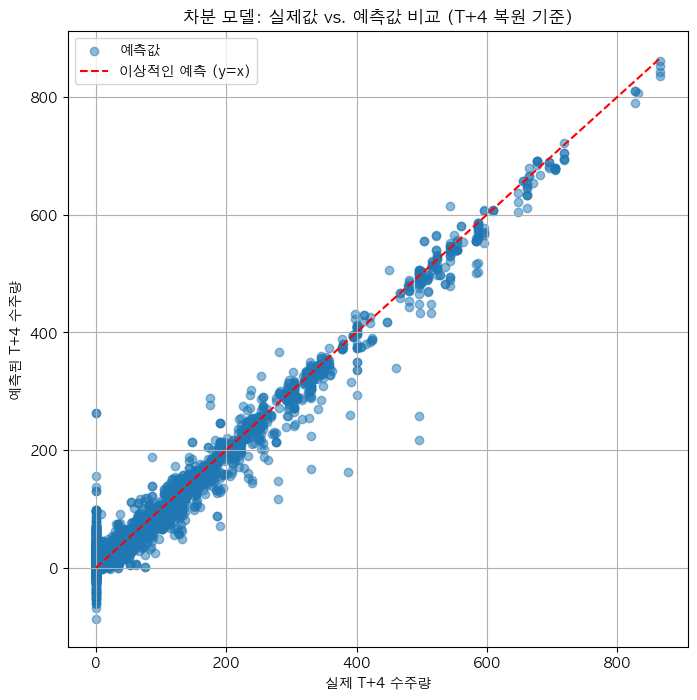

'diff_model_prediction_vs_actual.png' 저장 완료


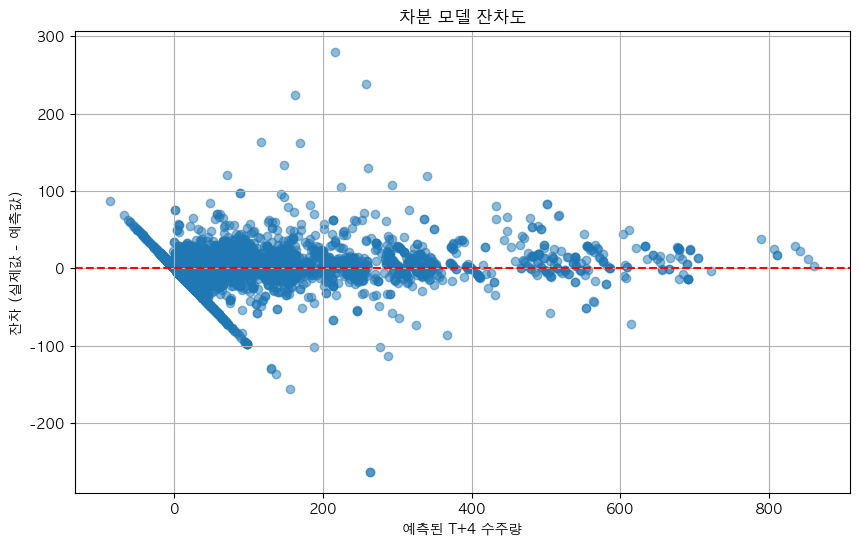

'diff_model_residual_plot.png' 저장 완료


In [47]:
# --- 5. 차분 모델 시각화 ---

print("\n--- 차분 모델 시각화 생성 ---")

# 1. 실제값 vs 예측값 비교 (복원된 T+4 값 기준)
plt.figure(figsize=(8, 8))
plt.scatter(t4_test_orig, restored_t4_preds, alpha=0.5, label='예측값')
plt.plot([min(t4_test_orig), max(t4_test_orig)], [min(t4_test_orig), max(t4_test_orig)], 'r--', label='이상적인 예측 (y=x)')
plt.title('차분 모델: 실제값 vs. 예측값 비교 (T+4 복원 기준)')
plt.xlabel('실제 T+4 수주량')
plt.ylabel('예측된 T+4 수주량')
plt.legend()
plt.grid(True)
plt.savefig('diff_model_prediction_vs_actual.png')
plt.show()
print("'diff_model_prediction_vs_actual.png' 저장 완료")


# 2. 잔차도 (Residual Plot)
residuals_diff = t4_test_orig - restored_t4_preds
plt.figure(figsize=(10, 6))
plt.scatter(restored_t4_preds, residuals_diff, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('차분 모델 잔차도')
plt.xlabel('예측된 T+4 수주량')
plt.ylabel('잔차 (실제값 - 예측값)')
plt.grid(True)
plt.savefig('diff_model_residual_plot.png')
plt.show()
print("'diff_model_residual_plot.png' 저장 완료")

In [48]:
import xgboost as xgb
import numpy as np

# --- 1. XGBoost 모델 정의 및 학습 ---
# XGBRegressor 모델을 생성합니다. n_estimators와 learning_rate는 튜닝 가능한 주요 하이퍼파라미터입니다.
xgboost_model = xgb.XGBRegressor(
    n_estimators=1000,         # 트리의 개수
    learning_rate=0.05,        # 학습률
    objective='reg:squarederror',
    n_jobs=-1,                 # 사용 가능한 모든 CPU 코어 사용
    random_state=42
)

print("--- XGBoost 베이스라인 모델 학습 시작 ---")

# 모델을 학습시킵니다. 조기 종료(Early Stopping)를 사용하여 과적합을 방지합니다.
# eval_set에는 검증용 데이터를 넣어 매 라운드마다 성능을 평가합니다.
xgboost_model.fit(
    X_train_d, 
    y_train_d,
    eval_set=[(X_test_d, y_test_d)],
    verbose=False             # 학습 과정을 출력하지 않음
)

print("XGBoost 모델 학습 완료.")


# --- 2. XGBoost 모델 평가 ---
print("\n--- XGBoost 모델 평가 ---")

# 테스트 데이터에 대해 차이값(difference)을 예측합니다.
predicted_diffs_xgb = xgboost_model.predict(X_test_d)

# 예측된 차이값을 실제 T+3 값에 더하여 T+4 예측을 복원합니다.
# t3_test_orig와 t4_test_orig는 이전 '차분 모델' 셀에서 생성된 변수입니다.
restored_t4_preds_xgb = t3_test_orig + predicted_diffs_xgb

# 복원된 T+4 예측값과 실제 T+4 값을 사용하여 최종 RMSE를 계산합니다.
xgb_model_rmse = np.sqrt(np.mean((t4_test_orig - restored_t4_preds_xgb)**2))


print("\n" + "="*50)
print(f"🚀 XGBoost 베이스라인 모델 최종 RMSE: {xgb_model_rmse:.4f}")
print("="*50)

# print(f"참고: 차분 베이스라인(PyTorch) RMSE: {diff_model_rmse:.4f}")
# print(f"참고: 차분 임베딩(PyTorch) RMSE: {embed_diff_model_rmse:.4f}")

--- XGBoost 베이스라인 모델 학습 시작 ---
XGBoost 모델 학습 완료.

--- XGBoost 모델 평가 ---

🚀 XGBoost 베이스라인 모델 최종 RMSE: 6.6812


In [40]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import torch.nn as nn
import torch.optim as optim

# --- 1. 차분을 적용한 데이터 전처리 (임베딩 모델용) ---

print("--- 차분(Differencing)을 적용한 임베딩 모델 준비 ---")

# 원본 데이터를 먼저 불러와 차분 타겟과 평가용 값을 저장합니다.
df_orig = pd.read_csv(FILE_PATH)
target_diff = df_orig['T+4일 예정 수주량'].values - df_orig['T+3일 예정 수주량'].values
original_t3_values = df_orig['T+3일 예정 수주량'].values
original_t4_values = df_orig['T+4일 예정 수주량'].values

# 피처 엔지니어링을 위한 데이터프레임
df_embed_diff = pd.read_csv(FILE_PATH)

# Product_Number를 정수 인덱스로 변환
product_ids = df_embed_diff['Product_Number'].unique()
product_map = {name: i for i, name in enumerate(product_ids)}
df_embed_diff['Product_Index'] = df_embed_diff['Product_Number'].map(product_map)
num_unique_products = len(product_ids)

# 시간 관련 피처 전처리
df_embed_diff['DateTime'] = pd.to_datetime(df_embed_diff['DateTime'], format='mixed')
df_embed_diff['month_sin'] = np.sin(2 * np.pi * df_embed_diff['DateTime'].dt.month/12)
df_embed_diff['month_cos'] = np.cos(2 * np.pi * df_embed_diff['DateTime'].dt.month/12)
df_embed_diff['day_sin'] = np.sin(2 * np.pi * df_embed_diff['DateTime'].dt.day/31)
df_embed_diff['day_cos'] = np.cos(2 * np.pi * df_embed_diff['DateTime'].dt.day/31)

# 수치형 피처 스케일링
scaler = MinMaxScaler()
numeric_cols = [col for col in df_embed_diff.columns if '수주량' in col] + ['Temperature', 'Humidity']
numeric_cols.remove('T+4일 예정 수주량') # 타겟은 스케일링에서 제외
cols_to_scale = [col for col in numeric_cols if col in df_embed_diff.columns]
if cols_to_scale:
    df_embed_diff[cols_to_scale] = scaler.fit_transform(df_embed_diff[cols_to_scale])

# DoW(요일) 원-핫 인코딩
df_embed_diff = pd.get_dummies(df_embed_diff, columns=['DoW'], prefix='DoW')

# 입력 피처 정의
product_input_d = df_embed_diff['Product_Index'].values
other_feature_cols_d = [col for col in df_embed_diff.columns if col not in ['Product_Number', 'Product_Index', 'DateTime', 'T+4일 예정 수주량']]
other_inputs_d = df_embed_diff[other_feature_cols_d].astype(np.float32).values

# --- 2. 데이터 분리 및 DataLoader 생성 ---

(p_train_d, p_test_d, o_train_d, o_test_d, 
 y_train_d, y_test_d, 
 t3_train_orig, t3_test_orig, 
 t4_train_orig, t4_test_orig) = train_test_split(
    product_input_d, other_inputs_d, 
    target_diff, original_t3_values, original_t4_values, 
    test_size=TEST_SPLIT_RATIO, random_state=42
)

# 임베딩 모델용 CustomDataset (이전 코드 재사용)
class CustomDataset(Dataset):
    def __init__(self, product_indices, other_features, targets):
        self.product_indices = torch.tensor(product_indices, dtype=torch.long)
        self.other_features = torch.tensor(other_features, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)
    def __len__(self): return len(self.targets)
    def __getitem__(self, idx): return self.product_indices[idx], self.other_features[idx], self.targets[idx]

train_loader_embed_d = DataLoader(CustomDataset(p_train_d, o_train_d, y_train_d), batch_size=BATCH_SIZE, shuffle=True)
test_loader_embed_d = DataLoader(CustomDataset(p_test_d, o_test_d, y_test_d), batch_size=BATCH_SIZE, shuffle=False)

# --- 3. 모델 학습 ---
# 모델 아키텍처는 model_pytorch.py의 EmbeddingModel 그대로 사용
from model import EmbeddingModel # model_pytorch.py 파일이 같은 경로에 있어야 합니다.

embed_diff_model = EmbeddingModel(
    num_unique_products=num_unique_products,
    embedding_dim=EMBEDDING_DIM, # 이전 셀에서 정의된 값 사용
    num_other_features=o_train_d.shape[1]
).to(DEVICE)

criterion_ed = nn.MSELoss()
optimizer_ed = optim.Adam(embed_diff_model.parameters(), lr=LEARNING_RATE)

print("\n--- 차분 타겟 임베딩 모델 학습 시작 ---")
for epoch in range(EPOCHS):
    embed_diff_model.train()
    for p_batch, o_batch, y_batch in train_loader_embed_d:
        optimizer_ed.zero_grad()
        outputs = embed_diff_model(p_batch.to(DEVICE), o_batch.to(DEVICE))
        loss = criterion_ed(outputs.squeeze(), y_batch.to(DEVICE))
        loss.backward()
        optimizer_ed.step()
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {loss.item():.4f}")

# --- 4. 차분 임베딩 모델 평가 ---
print("\n--- 차분 임베딩 모델 평가 ---")
embed_diff_model.eval()
predicted_diffs_embed = []
with torch.no_grad():
    for p_batch, o_batch, y_batch in test_loader_embed_d:
        outputs = embed_diff_model(p_batch.to(DEVICE), o_batch.to(DEVICE)).squeeze().cpu().numpy()
        predicted_diffs_embed.extend(outputs)

predicted_diffs_embed = np.array(predicted_diffs_embed)

# 예측된 차이값을 T+3에 더해 T+4 예측 복원
restored_t4_preds_embed = t3_test_orig + predicted_diffs_embed

# 최종 RMSE 계산
embed_diff_model_rmse = np.sqrt(np.mean((t4_test_orig - restored_t4_preds_embed)**2))

print("\n" + "="*60)
print(f"🏆 차분(Differencing) 적용 임베딩 모델 최종 RMSE: {embed_diff_model_rmse:.4f}")
print("="*60)

# print(f"참고: 차분 베이스라인 모델 RMSE: {diff_model_rmse:.4f}")

--- 차분(Differencing)을 적용한 임베딩 모델 준비 ---

--- 차분 타겟 임베딩 모델 학습 시작 ---
Epoch [10/100], Loss: 2543.4497
Epoch [20/100], Loss: 2442.0791
Epoch [30/100], Loss: 235.0742
Epoch [40/100], Loss: 4070.0962
Epoch [50/100], Loss: 911.6487
Epoch [60/100], Loss: 714.1729
Epoch [70/100], Loss: 244.6658
Epoch [80/100], Loss: 85.7038
Epoch [90/100], Loss: 251.6645
Epoch [100/100], Loss: 156.4526

--- 차분 임베딩 모델 평가 ---

🏆 차분(Differencing) 적용 임베딩 모델 최종 RMSE: 19.4702


In [44]:
import xgboost as xgb
import numpy as np

# --- 1. XGBoost 모델 정의 및 학습 ---
# XGBRegressor 모델을 생성합니다. n_estimators와 learning_rate는 튜닝 가능한 주요 하이퍼파라미터입니다.
xgboost_model = xgb.XGBRegressor(
    n_estimators=1000,         # 트리의 개수
    learning_rate=0.05,        # 학습률
    objective='reg:squarederror',
    n_jobs=-1,                 # 사용 가능한 모든 CPU 코어 사용
    random_state=42
)

print("--- XGBoost 베이스라인 모델 학습 시작 ---")

# 모델을 학습시킵니다. 조기 종료(Early Stopping)를 사용하여 과적합을 방지합니다.
# eval_set에는 검증용 데이터를 넣어 매 라운드마다 성능을 평가합니다.
xgboost_model.fit(
    X_train_d, 
    y_train_d,
    eval_set=[(X_test_d, y_test_d)],
    verbose=False             # 학습 과정을 출력하지 않음
)

print("XGBoost 모델 학습 완료.")


# --- 2. XGBoost 모델 평가 ---
print("\n--- XGBoost 모델 평가 ---")

# 테스트 데이터에 대해 차이값(difference)을 예측합니다.
predicted_diffs_xgb = xgboost_model.predict(X_test_d)

# 예측된 차이값을 실제 T+3 값에 더하여 T+4 예측을 복원합니다.
# t3_test_orig와 t4_test_orig는 이전 '차분 모델' 셀에서 생성된 변수입니다.
restored_t4_preds_xgb = t3_test_orig + predicted_diffs_xgb

# 복원된 T+4 예측값과 실제 T+4 값을 사용하여 최종 RMSE를 계산합니다.
xgb_model_rmse = np.sqrt(np.mean((t4_test_orig - restored_t4_preds_xgb)**2))


print("\n" + "="*50)
print(f"🚀 XGBoost 베이스라인 모델 최종 RMSE: {xgb_model_rmse:.4f}")
print("="*50)

# print(f"참고: 차분 베이스라인(PyTorch) RMSE: {diff_model_rmse:.4f}")
# print(f"참고: 차분 임베딩(PyTorch) RMSE: {embed_diff_model_rmse:.4f}")

--- XGBoost 베이스라인 모델 학습 시작 ---
XGBoost 모델 학습 완료.

--- XGBoost 모델 평가 ---

🚀 XGBoost 베이스라인 모델 최종 RMSE: 6.6812


--- 제품별 개별 XGBoost 모델 성능 편차 분석 시작 ---

         제품별 XGBoost 모델 성능 평가 결과
   Product      RMSE        MAPE  Num_Samples
Product_e3 42.609505    9.098056          305
Product_ee 29.437645   41.639190          305
Product_ef 26.376379    5.895470          305
Product_c8 16.166096   10.193694          305
Product_a0 14.863639    3.220517          305
Product_c7  8.508513    1.195038          305
Product_88  8.283082    0.664371          305
Product_cf  8.236861 1070.908317          305
Product_a6  7.332256    1.924743          305
Product_ec  6.361314    1.375093          305
Product_99  5.355078  238.417814          610
Product_b6  5.050143    6.494532          305
Product_df  4.566474  584.716497          305
Product_c3  3.484672    0.348596          305
Product_e2  2.824867    4.497396          305
Product_cd  2.624507  391.227094          305
Product_ca  2.419442    0.887006          305
Product_dc  2.395813    2.925539          305
Product_95  2.213273    1.366503          305
Product_

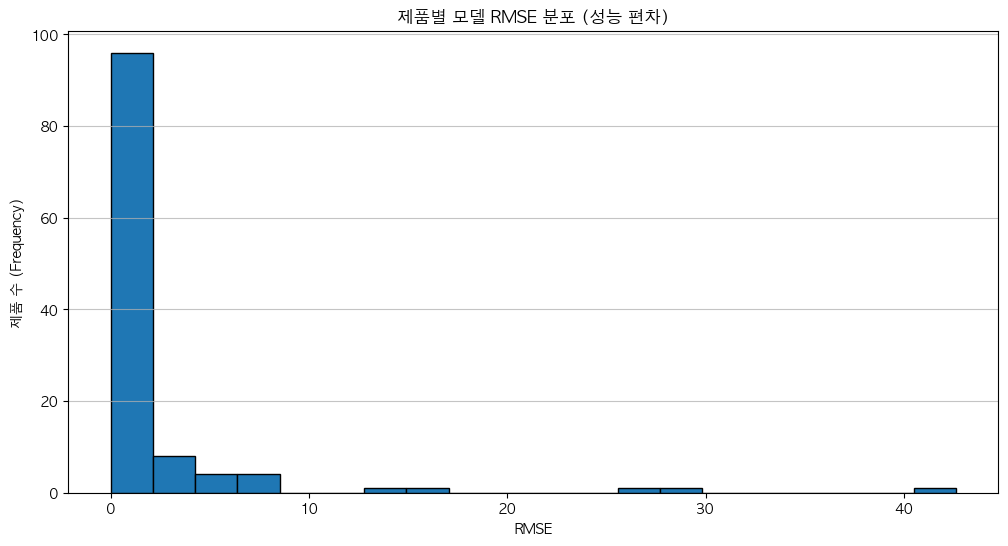


'product_rmse_distribution.png' 저장 완료.


In [54]:
import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

print("--- 제품별 개별 XGBoost 모델 성능 편차 분석 시작 ---")

# 1. 데이터 로드 및 기본 전처리
df_full = pd.read_csv(FILE_PATH)
df_full['DateTime'] = pd.to_datetime(df_full['DateTime'], format='mixed')
df_full['month_sin'] = np.sin(2 * np.pi * df_full['DateTime'].dt.month/12)
df_full['month_cos'] = np.cos(2 * np.pi * df_full['DateTime'].dt.month/12)
df_full['day_sin'] = np.sin(2 * np.pi * df_full['DateTime'].dt.day/31)
df_full['day_cos'] = np.cos(2 * np.pi * df_full['DateTime'].dt.day/31)

df_full['target_diff'] = df_full['T+4일 예정 수주량'] - df_full['T+3일 예정 수주량']

unique_products = df_full['Product_Number'].unique()
results = []

# 2. 각 제품별로 모델 학습 및 평가 반복
for product in unique_products:
    df_product = df_full[df_full['Product_Number'] == product].copy()
    
    # 학습에 필요한 최소 데이터 샘플 수 확인 (예: 20개 미만은 건너뛰기)
    if len(df_product) < 20:
        print(f"'{product}'는 샘플 수가 {len(df_product)}개로 부족하여 분석에서 제외합니다.")
        continue

    # DoW(요일) 원-핫 인코딩
    df_product = pd.get_dummies(df_product, columns=['DoW'], prefix='DoW')

    # 입력 피처 정의 (제품 ID는 필요 없음)
    features_to_exclude = ['Product_Number', 'DateTime', 'T+4일 예정 수주량', 'target_diff']
    feature_cols = [col for col in df_product.columns if col not in features_to_exclude]
    
    X = df_product[feature_cols].astype(np.float32)
    y = df_product['target_diff']
    
    # 평가를 위한 원본 값
    t3_orig = df_product['T+3일 예정 수주량']
    t4_orig = df_product['T+4일 예정 수주량']

    # 데이터 분리
    X_train, X_test, y_train, y_test, t3_train, t3_test, t4_train, t4_test = train_test_split(
        X, y, t3_orig, t4_orig, test_size=0.2, random_state=42
    )

    # 모델 학습
    model = xgb.XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        objective='reg:squarederror',
        n_jobs=-1,
        random_state=42
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_test, y_test)],
        verbose=False
    )
    
    # 평가
    preds_diff = model.predict(X_test)
    preds_restored = t3_test + preds_diff
    rmse = np.sqrt(np.mean((t4_test - preds_restored)**2))
    mape = np.mean(np.abs((t4_test - preds_restored) / (t4_test+0.1))) * 100
    
    results.append({
        'Product': product,
        'RMSE': rmse,
        'MAPE': mape,
        'Num_Samples': len(df_product)
    })

# 3. 결과 정리 및 분석
results_df = pd.DataFrame(results).sort_values(by='RMSE', ascending=False)

print("\n" + "="*50)
print("         제품별 XGBoost 모델 성능 평가 결과")
print("="*50)
print(results_df.to_string(index=False))

print("\n" + "="*50)
print("              성능 편차 요약 통계")
print("="*50)
print(results_df['RMSE'].describe())


# 4. 성능 편차 시각화
plt.figure(figsize=(12, 6))
plt.hist(results_df['RMSE'], bins=20, edgecolor='black')
plt.title('제품별 모델 RMSE 분포 (성능 편차)')
plt.xlabel('RMSE')
plt.ylabel('제품 수 (Frequency)')
plt.grid(axis='y', alpha=0.75)
plt.savefig('product_rmse_distribution.png')
plt.show()

print("\n'product_rmse_distribution.png' 저장 완료.")

--- 통계량 기반 클러스터링 및 그룹별 모델링 시작 ---
--- 클러스터 시각화 및 통계량 분석 시작 ---


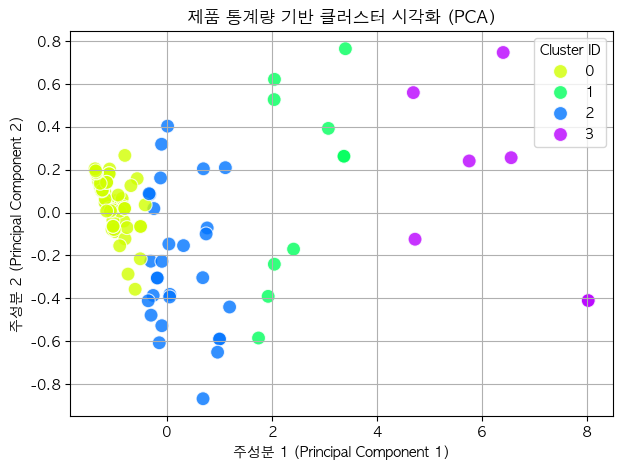


'product_cluster_visualization.png' 저장 완료.

              클러스터별 통계량 특성 요약
각 클러스터의 통계량 평균값을 통해 그룹의 성격을 파악할 수 있습니다.
           평균(mean)  중앙값(median)   표준편차(std)  최소값(min)    최대값(max)
Cluster                                                           
0         10.108668     6.366197   12.341657       0.0   43.521127
1        180.758033   222.100000  124.614801       0.0  359.200000
2         63.991331    55.379310   62.139909       0.0  184.000000
3        316.216862   464.142857  277.249549       0.0  664.428571


In [30]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import seaborn as sns
from sklearn.manifold import TSNE


plt.rc('font', family='AppleGothic') 
plt.rc('axes', unicode_minus=False) # 마이너스 폰트 깨짐 방지

print("--- 통계량 기반 클러스터링 및 그룹별 모델링 시작 ---")

# 1. 데이터 로드 및 타겟 변수 생성
FILE_PATH = 'data/사출성형_공급망최적화.csv'
df_full = pd.read_csv(FILE_PATH)
df_full['target_diff'] = df_full['T+4일 예정 수주량']

# 2. 제품별 통계량 계산
stats = df_full.groupby('Product_Number')['target_diff'].agg(['mean', 'median', 'std', 'min', 'max']).fillna(0)

# 3. 통계량 기반 클러스터링
# 클러스터링을 위해 통계량 데이터를 표준화합니다.
scaler = StandardScaler()
stats_scaled = scaler.fit_transform(stats)

# K-Means 클러스터링 수행 (클러스터 개수는 데이터에 맞게 조절 가능)
N_CLUSTERS = 4 
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
stats['Cluster'] = kmeans.fit_predict(stats_scaled)

# 이전 셀에서 생성된 'stats'와 'N_CLUSTERS' 변수를 사용합니다.
# 만약 세션이 끊겼다면, 이전 클러스터링 모델 코드를 먼저 실행해야 합니다.

print("--- 클러스터 시각화 및 통계량 분석 시작 ---")

# 1. PCA를 이용한 차원 축소
# 이전에 클러스터링에 사용했던 스케일링된 데이터를 사용합니다.
pca = PCA(n_components=2, random_state=42)
stats_pca = pca.fit_transform(stats_scaled)

# PCA 결과를 데이터프레임에 추가
stats['pca1'] = stats_pca[:, 0]
stats['pca2'] = stats_pca[:, 1]


# 2. 클러스터 시각화
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=stats,
    x='pca1',
    y='pca2',
    hue='Cluster',
    palette=sns.color_palette("hsv", N_CLUSTERS),
    s=100, # 점 크기
    alpha=0.8 # 투명도
)
plt.title('제품 통계량 기반 클러스터 시각화 (PCA)')
plt.xlabel('주성분 1 (Principal Component 1)')
plt.ylabel('주성분 2 (Principal Component 2)')
plt.legend(title='Cluster ID')
plt.grid(True)
plt.savefig('product_cluster_visualization.png')
plt.show()
print("\n'product_cluster_visualization.png' 저장 완료.")


# 3. 클러스터별 특성 분석
# 각 클러스터에 속한 제품들의 통계량 평균을 계산하여 그룹의 특성을 파악합니다.
cluster_summary = stats.groupby('Cluster').agg({
    'mean': 'mean',
    'median': 'mean',
    'std': 'mean',
    'min': 'mean',
    'max': 'mean'
}).rename(columns={
    'mean': '평균(mean)',
    'median': '중앙값(median)',
    'std': '표준편차(std)',
    'min': '최소값(min)',
    'max': '최대값(max)'
})

print("\n" + "="*60)
print("              클러스터별 통계량 특성 요약")
print("="*60)
print("각 클러스터의 통계량 평균값을 통해 그룹의 성격을 파악할 수 있습니다.")
print(cluster_summary)

--- 통계량 기반 클러스터링 및 그룹별 모델링 시작 ---
--- 클러스터 시각화 및 통계량 분석 시작 ---


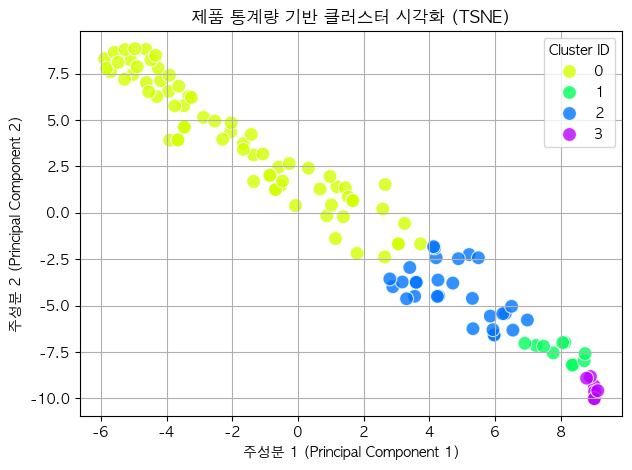


'product_cluster_visualization.png' 저장 완료.

              클러스터별 통계량 특성 요약
각 클러스터의 통계량 평균값을 통해 그룹의 성격을 파악할 수 있습니다.
           평균(mean)  중앙값(median)   표준편차(std)  최소값(min)    최대값(max)
Cluster                                                           
0         10.108668     6.366197   12.341657       0.0   43.521127
1        180.758033   222.100000  124.614801       0.0  359.200000
2         63.991331    55.379310   62.139909       0.0  184.000000
3        316.216862   464.142857  277.249549       0.0  664.428571


In [18]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE


plt.rc('font', family='AppleGothic') 
plt.rc('axes', unicode_minus=False) # 마이너스 폰트 깨짐 방지

print("--- 통계량 기반 클러스터링 및 그룹별 모델링 시작 ---")

# 1. 데이터 로드 및 타겟 변수 생성
FILE_PATH = 'data/사출성형_공급망최적화.csv'
df_full = pd.read_csv(FILE_PATH)
df_full['target_diff'] = df_full['T+4일 예정 수주량']

# 2. 제품별 통계량 계산
stats = df_full.groupby('Product_Number')['target_diff'].agg(['mean', 'median', 'std', 'min', 'max']).fillna(0)

# 3. 통계량 기반 클러스터링
# 클러스터링을 위해 통계량 데이터를 표준화합니다.
scaler = StandardScaler()
stats_scaled = scaler.fit_transform(stats)

# K-Means 클러스터링 수행 (클러스터 개수는 데이터에 맞게 조절 가능)
N_CLUSTERS = 4 
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
stats['Cluster'] = kmeans.fit_predict(stats_scaled)

# 이전 셀에서 생성된 'stats'와 'N_CLUSTERS' 변수를 사용합니다.
# 만약 세션이 끊겼다면, 이전 클러스터링 모델 코드를 먼저 실행해야 합니다.

print("--- 클러스터 시각화 및 통계량 분석 시작 ---")

# 1. tsne를 이용한 차원 축소
# 이전에 클러스터링에 사용했던 스케일링된 데이터를 사용합니다.
tsne = TSNE(n_components=2, random_state=42)
stats_tsne = tsne.fit_transform(stats_scaled)

# tsne 결과를 데이터프레임에 추가
stats['tsne1'] = stats_tsne[:, 0]
stats['tsne2'] = stats_tsne[:, 1]


# 2. 클러스터 시각화
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=stats,
    x='tsne1',
    y='tsne2',
    hue='Cluster',
    palette=sns.color_palette("hsv", N_CLUSTERS),
    s=100, # 점 크기
    alpha=0.8 # 투명도
)
plt.title('제품 통계량 기반 클러스터 시각화 (TSNE)')
plt.xlabel('주성분 1 (Principal Component 1)')
plt.ylabel('주성분 2 (Principal Component 2)')
plt.legend(title='Cluster ID')
plt.grid(True)
plt.savefig('product_cluster_visualization.png')
plt.show()
print("\n'product_cluster_visualization.png' 저장 완료.")


# 3. 클러스터별 특성 분석
# 각 클러스터에 속한 제품들의 통계량 평균을 계산하여 그룹의 특성을 파악합니다.
cluster_summary = stats.groupby('Cluster').agg({
    'mean': 'mean',
    'median': 'mean',
    'std': 'mean',
    'min': 'mean',
    'max': 'mean'
}).rename(columns={
    'mean': '평균(mean)',
    'median': '중앙값(median)',
    'std': '표준편차(std)',
    'min': '최소값(min)',
    'max': '최대값(max)'
})

print("\n" + "="*60)
print("              클러스터별 통계량 특성 요약")
print("="*60)
print("각 클러스터의 통계량 평균값을 통해 그룹의 성격을 파악할 수 있습니다.")
print(cluster_summary)

--- HDBSCAN을 이용한 동적 클러스터링 분석 시작 ---

HDBSCAN 분석 결과, 총 '5'개의 클러스터와 '71'개의 노이즈(이상치)를 발견했습니다.

--- 클러스터별 제품 수 ---
Cluster
-1    71
 0    10
 1     8
 2     7
 3    16
 4     5
Name: count, dtype: int64


/Users/jihyeok/.pyenv/versions/3.9.6/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/jihyeok/.pyenv/versions/3.9.6/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


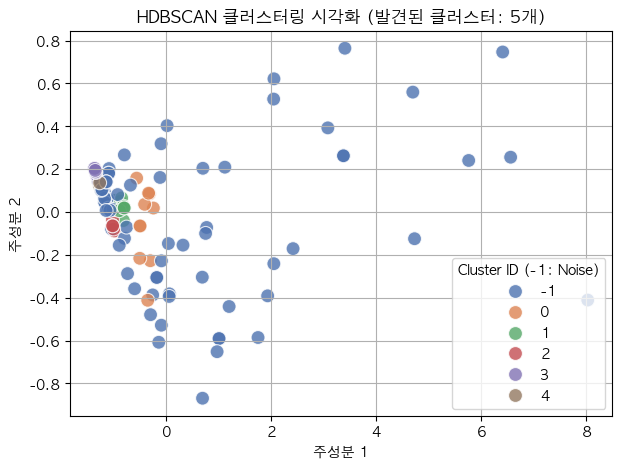

'hdbscan_cluster_visualization.png' 저장 완료.

       HDBSCAN으로 찾은 5개 클러스터의 통계량 특성 요약
클러스터 ID '-1'은 노이즈(이상치)로 분류된 제품들입니다.
                평균        중앙값       표준편차  최소값         최대값
Cluster                                                  
0        39.291803  33.700000  35.756533  0.0  115.500000
1        19.856148  14.625000  20.629030  0.0   63.875000
2         7.721780   0.428571  17.655010  0.0   64.142857
3         0.344646   0.000000   0.855938  0.0    3.312500
4         2.097841   0.000000   4.724340  0.0   18.800000


In [19]:
# HDBSCAN 라이브러리가 없다면 먼저 설치해야 합니다.
# !pip install hdbscan

import pandas as pd
import numpy as np
import hdbscan
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

print("--- HDBSCAN을 이용한 동적 클러스터링 분석 시작 ---")

# 1. 데이터 로드 및 통계량 계산 (이전과 동일)
df_full = pd.read_csv(FILE_PATH)
df_full['target_diff'] = df_full['T+4일 예정 수주량']
stats = df_full.groupby('Product_Number')['target_diff'].agg(['mean', 'median', 'std', 'min', 'max']).fillna(0)
scaler = StandardScaler()
stats_scaled = scaler.fit_transform(stats)

# 2. HDBSCAN 모델 생성 및 학습
# min_cluster_size: 클러스터로 인정받기 위한 최소 샘플(제품) 수
# 이 값에 따라 클러스터의 개수와 노이즈 판단이 달라집니다.
hdb = hdbscan.HDBSCAN(min_cluster_size=5, gen_min_span_tree=True)
cluster_labels = hdb.fit_predict(stats_scaled)

stats['Cluster'] = cluster_labels

# 3. 클러스터링 결과 요약
num_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
num_noise = np.sum(cluster_labels == -1)

print(f"\nHDBSCAN 분석 결과, 총 '{num_clusters}'개의 클러스터와 '{num_noise}'개의 노이즈(이상치)를 발견했습니다.")
print("\n--- 클러스터별 제품 수 ---")
print(stats['Cluster'].value_counts().sort_index())


# 4. 클러스터 시각화 (PCA)
pca = PCA(n_components=2, random_state=42)
stats_pca = pca.fit_transform(stats_scaled)
stats['pca1'] = stats_pca[:, 0]
stats['pca2'] = stats_pca[:, 1]

plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=stats,
    x='pca1',
    y='pca2',
    hue='Cluster',
    palette=sns.color_palette("deep", n_colors=num_clusters + 1), # 노이즈(-1) 포함
    s=100,
    alpha=0.8
)
plt.title(f'HDBSCAN 클러스터링 시각화 (발견된 클러스터: {num_clusters}개)')
plt.xlabel('주성분 1')
plt.ylabel('주성분 2')
plt.legend(title='Cluster ID (-1: Noise)')
plt.grid(True)
plt.savefig('hdbscan_cluster_visualization.png')
plt.show()
print("'hdbscan_cluster_visualization.png' 저장 완료.")


# 5. 클러스터별 특성 분석 (노이즈 제외)
cluster_summary = stats[stats['Cluster'] != -1].groupby('Cluster').agg({
    'mean': 'mean', 'median': 'mean', 'std': 'mean', 'min': 'mean', 'max': 'mean'
}).rename(columns={'mean': '평균', 'median': '중앙값', 'std': '표준편차', 'min': '최소값', 'max': '최대값'})

print("\n" + "="*60)
print(f"       HDBSCAN으로 찾은 {num_clusters}개 클러스터의 통계량 특성 요약")
print("="*60)
print("클러스터 ID '-1'은 노이즈(이상치)로 분류된 제품들입니다.")
print(cluster_summary)

--- 클러스터별 XGBoost 모델 학습 및 평가 시작 ---

--- Cluster 0 모델 학습 및 평가 ---

--- Cluster 1 모델 학습 및 평가 ---

--- Cluster 2 모델 학습 및 평가 ---

--- Cluster 3 모델 학습 및 평가 ---

                  클러스터별 모델 성능 요약
 Cluster_ID       RMSE  Num_Products  Num_Samples
          0  20.316269            71        19985
          1 204.377249            10         3660
          2  87.754710            29         8837
          3 380.760469             7         2135

📈 통계량 기반 클러스터링 모델의 최종 통합 RMSE: 124.7449


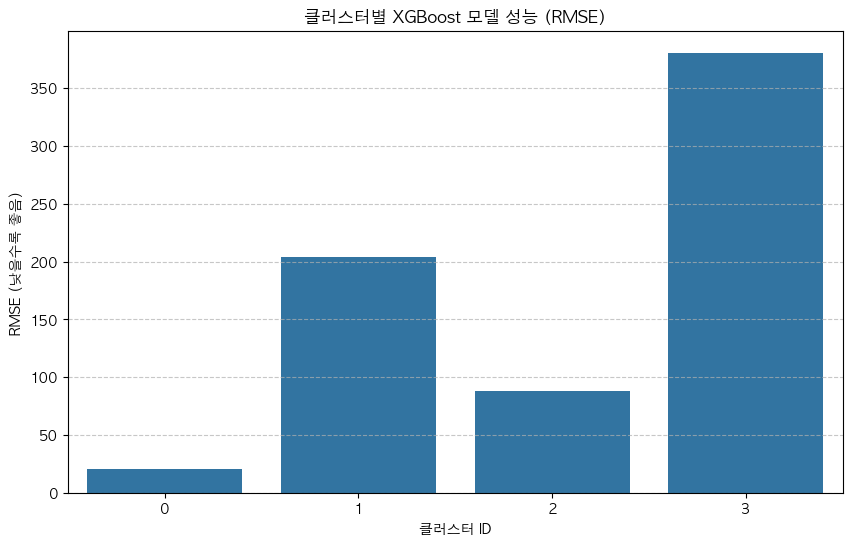


'cluster_model_performance.png' 저장 완료.


In [34]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# 이전 셀에서 생성된 df_full, stats, N_CLUSTERS 변수를 사용합니다.
print("--- 클러스터별 XGBoost 모델 학습 및 평가 시작 ---")

# 1. 원본 데이터프레임에 클러스터 정보 추가
# df_full = df_full.merge(stats['Cluster'], on='Product_Number', how='left')
# df_full = df_full.drop(['Cluster_x', 'Cluster_y'], axis=1)

# 2. 클러스터별 모델 학습 및 평가
cluster_results = []
all_preds, all_reals = [], []

for cluster_id in range(N_CLUSTERS):
    print(f"\n--- Cluster {cluster_id} 모델 학습 및 평가 ---")
    df_cluster = df_full[df_full['Cluster'] == cluster_id].copy()

    # 데이터가 너무 적은 경우 건너뛰기
    if len(df_cluster) < 50:
        print(f"Cluster {cluster_id}는 샘플 수가 {len(df_cluster)}개로 부족하여 모델링을 건너뜁니다.")
        continue
    
    # 기본 전처리
    df_cluster['DateTime'] = pd.to_datetime(df_cluster['DateTime'], format='mixed')
    df_cluster['month_sin'] = np.sin(2 * np.pi * df_cluster['DateTime'].dt.month/12)
    df_cluster['month_cos'] = np.cos(2 * np.pi * df_cluster['DateTime'].dt.month/12)
    df_cluster['day_sin'] = np.sin(2 * np.pi * df_cluster['DateTime'].dt.day/31)
    df_cluster['day_cos'] = np.cos(2 * np.pi * df_cluster['DateTime'].dt.day/31)
    df_cluster = pd.get_dummies(df_cluster, columns=['DoW'], prefix='DoW')

    # 피처/타겟 정의
    features_to_exclude = ['Product_Number', 'DateTime', 'T+4일 예정 수주량', 'target_diff', 'Cluster']
    feature_cols = [col for col in df_cluster.columns if col not in features_to_exclude]
    X = df_cluster[feature_cols].astype(np.float32)
    y = df_cluster['target_diff']
    t3_orig = df_cluster['T+3일 예정 수주량']
    t4_orig = df_cluster['T+4일 예정 수주량']

    # 추천하는 수정안
    X_train, X_test, y_train, y_test, _, t3_test, _, t4_test = train_test_split(
        X, y, t3_orig, t4_orig, test_size=0.2, random_state=42
    )

    # 모델 학습
    model = xgb.XGBRegressor(n_estimators=1000, learning_rate=0.05, n_jobs=-1, random_state=42)
    model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
    
    # 평가
    preds_diff = model.predict(X_test)
    preds_restored = t3_test.values + preds_diff # .values를 추가하여 Series와 ndarray 연산 보장
    rmse = np.sqrt(np.mean((t4_test.values - preds_restored)**2))
    
    cluster_results.append({
        'Cluster_ID': cluster_id, 
        'RMSE': rmse, 
        'Num_Products': df_cluster['Product_Number'].nunique(),
        'Num_Samples': len(df_cluster)
    })
    
    all_preds.extend(preds_restored)
    all_reals.extend(t4_test.values)

# 3. 최종 결과 분석 및 요약
results_df = pd.DataFrame(cluster_results)

print("\n" + "="*60)
print("                  클러스터별 모델 성능 요약")
print("="*60)
print(results_df.to_string(index=False))

# 전체 테스트 데이터에 대한 통합 RMSE 계산
overall_rmse = np.sqrt(np.mean((np.array(all_reals) - np.array(all_preds))**2))

print("\n" + "="*60)
print(f"📈 통계량 기반 클러스터링 모델의 최종 통합 RMSE: {overall_rmse:.4f}")
print("="*60)


# 4. 클러스터별 성능 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x='Cluster_ID', y='RMSE', data=results_df.sort_values('Cluster_ID'))
plt.title('클러스터별 XGBoost 모델 성능 (RMSE)')
plt.xlabel('클러스터 ID')
plt.ylabel('RMSE (낮을수록 좋음)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('cluster_model_performance.png')
plt.show()

print("\n'cluster_model_performance.png' 저장 완료.")